### 1. Data Ingestion & Initial Inspection
We loaded the dataset to inspect its structure, verifying the total number of records (rows) and attributes (columns). 
This initial check helps identify feature types (numerical, categorical, and temporal) as well as the immediate presence of missing values.
Below we display the first 5 rows to understand the data layout.

In [10]:
import pandas as pd
import numpy as np
trainFile = "/Users/renata/Library/CloudStorage/OneDrive-NOVAIMS/mestrado/1semestre/AprendizagemAutomatica(S1)/ProjectML/ML_Grupo18/data/train.csv"
df = pd.read_csv(trainFile)

print("Dataset Dimention (Rows, Columns):", df.shape)

print("\n--- First 5 Rows ---")
df.head()

Dataset Dimention (Rows, Columns): (6534, 39)

--- First 5 Rows ---


,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,...,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,ID,random_noise
0,558.11,510.90,453.75,104.36,0.0,0.0,57.15,153.099911,4.0,1.0,...,660784,Maybe Tomorrow Payment 10,VLOOKUP Master 9,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2024-10-29,10000000,-0.660448
1,978.80,830.02,795.77,183.03,0.0,0.0,34.25,472.943134,32.0,1.0,...,189146,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 36,Final Excel Warehouse 1,Ctrl Z Series 1,2017-07-08,10000001,0.924510
2,10.33,12.00,8.40,1.93,0.0,0.0,3.60,6.097485,1.0,1.0,...,103940,Maybe Tomorrow Payment 9,VLOOKUP Master 1,Decorative Dashboard Zone 4,NaN,Final Excel Warehouse 1,Ctrl Z Series 3,2019-03-19,10000002,-0.258730
3,856.83,696.61,696.61,160.22,0.0,0.0,0.00,408.167275,9.0,1.0,...,512927,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 71,Final Excel Warehouse 1,Ctrl Z Series 3,2018-11-10,10000003,1.448402
4,1616.10,1488.85,1313.90,302.20,0.0,0.0,174.95,485.401864,33.0,1.0,...,122356,Maybe Tomorrow Payment 12,NaN,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2021-11-30,10000004,-1.058890


### 1.1. Feature Overview & Data Types
The following code snippet displays the full list of features, their respective non-null counts, and inferred data types.

In [11]:
print("\n--- Datatype Information ---")
print(df.info())


--- Datatype Information ---
<class 'pandas.DataFrame'>
RangeIndex: 6534 entries, 0 to 6533
Data columns (total 39 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Total a Pagar                   6469 non-null   float64
 1   Total Bruto                     6469 non-null   float64
 2   Total Liquido                   6469 non-null   float64
 3   Total Imp_                      6469 non-null   float64
 4   Total Portes                    6469 non-null   float64
 5   Total Desc_ Global              6469 non-null   float64
 6   Total Desc_ Linha               6469 non-null   float64
 7   Custo                           6469 non-null   float64
 8   N_ Detalhes                     6469 non-null   float64
 9   invoice_count_current_purchase  6469 non-null   float64
 10  repeat_purchase_90d             6534 non-null   int64  
 11  days_since_previous_purchase    5673 non-null   float64
 12  customer_tenure

### 1.2. Analysis of Duplicates and Customer Repeat Purchases

To ensure data integrity and understand the granularity of our dataset, we performed two key checks:
1. **Full Row Duplicates (`df.duplicated()`):** We checked for exact duplicate entries across all columns in the df dataset. Finding zero full duplicates confirms that every record represents a unique invoice/transaction event.
2. **Granularity & Customer Repetition (`customer_id`):** We examined the frequency of transactions per customer (`customer_id`). Multiple records sharing the same `customer_id` do not indicate data errors, but rather reflect returning customers who made multiple purchases over time.

Analyzing the distribution of purchases per customer helps validate the transactional nature of the dataset and aligns directly with our modeling objective of predicting customer repeat purchases.

In [12]:
duplicate_rows = df.duplicated().sum()
print("duplicates ignoring the index:", duplicate_rows)

per_customer = df.groupby("customer_id").size()

print(f"\nsurplus rows on 'customer_id': {df.duplicated(subset='customer_id').sum()}")
print(f"rows sharing a 'customer_id': {per_customer[per_customer > 1].sum()} across {(per_customer > 1).sum()} customers")

# print("records per customer:", per_customer.value_counts().to_dict())
bins = [0, 1, 2, 5, 10, 20, 50, 100, 300]
labels = [
    '1 purchase', 
    '2 purchases', 
    '3-5 purchases', 
    '6-10 purchases', 
    '11-20 purchases', 
    '21-50 purchases', 
    '51-100 purchases', 
    '>100 purchases'
]

customer_bins = pd.cut(per_customer, bins=bins, labels=labels).value_counts().sort_index()

print("\nrecords per customer (binned distribution):")
print(customer_bins.to_dict())

duplicates ignoring the index: 0

surplus rows on 'customer_id': 5924
rows sharing a 'customer_id': 6377 across 453 customers

records per customer (binned distribution):
{'1 purchase': 157, '2 purchases': 84, '3-5 purchases': 119, '6-10 purchases': 84, '11-20 purchases': 73, '21-50 purchases': 70, '51-100 purchases': 20, '>100 purchases': 3}


### 1.3. Missing Value Analysis
To assess overall data completeness in the raw dataset, we generated a high-level summary of missing values (`NaN`).

This overview quantifies:
* **Rows with at least one missing value** (total count and percentage of the dataset).
* **Columns containing missing values** out of the total feature set.
* **Total missing cells** across the entire data frame.
* **The feature with the highest count of missing values** (`worst column`).

This summary establishes an initial baseline of data quality prior to any cleaning or imputation steps.

In [13]:
rows_with_null = df.isna().any(axis=1)
per_column = df.isna().sum()

pd.Series({
    "rows with a null": f"{rows_with_null.sum():,} of {len(df):,} ({100 * rows_with_null.mean():.2f}%)",
    "columns with a null": f"{(per_column > 0).sum()} of {df.shape[1]}",
    "null cells": f"{df.isna().sum().sum():,}",
    "worst column": f"{per_column.idxmax()} ({per_column.max()} nulls)",
}).to_frame("missing values as the file arrives")

,missing values as the file arrives
rows with a null,"2,605 of 6,534 (39.87%)"
columns with a null,36 of 39
null cells,"9,818"
worst column,prior_std_gap_days (1478 nulls)


### 1.4. Identification and Handling of Domain Inconsistencies (Negative Values)

In domain-specific feature engineering, certain numerical attributes—such as days elapsed, monetary amounts, and purchase values—must be non-negative by definition.

We identified columns where negative values represent domain inconsistencies or data anomalies:
* `days_since_previous_purchase`
* `prior_mean_purchase_value`
* `prior_mean_gap_days`
* `spend_365d`

To evaluate the impact of these anomalies, we temporarily replace negative values with `NaN` using `.mask(< 0)` and quantify how this transformation affects the total count of missing rows and missing cells across the dataset.


In [14]:
# Define numerical columns whose domain strictly forbids negative values
non_negative = [
    "days_since_previous_purchase", 
    "prior_mean_purchase_value", 
    "prior_mean_gap_days", 
    "spend_365d"
]

# Convert negative values in these columns to NaN to evaluate anomalies
df_cleaned = df.copy()
df_cleaned[non_negative] = df_cleaned[non_negative].mask(df_cleaned[non_negative] < 0)

# Calculate the impact on missing value counts
rows_before = df.isna().any(axis=1).sum()
rows_after = df_cleaned.isna().any(axis=1).sum()
cells_before = df.isna().sum().sum()
cells_after = df_cleaned.isna().sum().sum()

print(f"\nrows with a null: {rows_before:,} -> {rows_after:,} ({100 * rows_after / len(df):.2f}% of {len(df):,})")
print(f"null cells:       {cells_before:,} -> {cells_after:,}")




rows with a null: 2,605 -> 2,643 (40.45% of 6,534)
null cells:       9,818 -> 9,881


COMPLETAR DEPOIS DE CORRER O CODIGO!!!!!!!!!!!!!!!!!!!!!!

Identificação de Dados Inválidos: No contexto do negócio, métricas como o número de dias desde a última compra (days_since_previous_purchase), o valor médio de compras anteriores (prior_mean_purchase_value), o intervalo médio entre compras (prior_mean_gap_days) e o gasto acumulado nos últimos 365 dias (spend_365d) não podem assumir valores inferiores a zero.   Tratamento por Invalidação: Os registos com valores negativos nestas colunas representam anomalias na recolha de dados. Em vez de apagar as linhas inteiras ou ignorar os erros, converteu-se esses valores específicos em NaN (missing values) para serem devidamente imputados na fase de pré-processamento.   Impacto no Dataset: Após a conversão, o número de linhas com pelo menos um valor omisso subiu ligeiramente de 2 605 para 2 643 (40,45% do total de observações), e o número total de células nulas passou de 9 818 para 9 881.

### 1.5 Descriptive Statistics
To fulfill the exploratory data analysis requirements, we generated descriptive summary statistics for all numerical features in the dataset. 

* **What it does:** The df.describe() function computes key statistical metrics—including the count, mean, standard deviation, minimum, maximum, and interquartile percentiles (25%, 50% median, and 75%)—for every numerical column.

* **Why we use it:** It allows us to quickly assess the central tendency and dispersion of our features, identify potential scale discrepancies, and spot initial anomalies or extreme outliers across monetary values, counts, and temporal gaps before proceeding to data cleaning.


In [15]:
# Display summary statistics for numerical features in the raw dataset
df.describe()

,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,...,spend_30d,purchase_count_90d,spend_90d,purchase_count_180d,spend_180d,purchase_count_365d,spend_365d,customer_id,ID,random_noise
count,6469.000000,6469.000000,6469.000000,6469.000000,6469.000000,6469.000000,6469.000000,6469.000000,6469.000000,6469.000000,...,6469.000000,6469.000000,6469.000000,6469.000000,6469.000000,6469.000000,6.274000e+03,6534.000000,6.534000e+03,6469.000000
mean,925.556262,886.152705,773.336384,152.219878,1.151427,0.349907,112.466414,328.165040,21.524501,1.066007,...,457.141009,1.631937,1253.527977,3.374556,2650.599796,6.561601,2.396535e+06,506471.910621,1.000383e+07,-0.022140
std,1334.997733,1327.641086,1136.355723,225.262375,5.844091,5.116564,289.986307,519.507218,27.713419,0.310807,...,1191.231401,2.977981,2347.842270,5.460510,4020.267397,10.325535,4.884113e+07,266556.041526,2.218817e+03,1.001054
min,0.930000,0.830000,0.760000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-1.591152e+05,103940.000000,1.000000e+07,-3.529210
25%,188.920000,175.740000,154.380000,29.930000,0.000000,0.000000,0.000000,49.050000,4.000000,1.000000,...,0.000000,0.000000,0.000000,1.000000,149.160000,1.000000,6.377825e+02,258332.000000,1.000191e+07,-0.677770
50%,476.740000,445.740000,389.910000,79.740000,0.000000,0.000000,13.130000,152.540000,11.000000,1.000000,...,0.000000,1.000000,198.500000,2.000000,1117.680000,3.000000,2.426605e+03,489625.000000,1.000382e+07,-0.045714
75%,1087.670000,1036.700000,903.370000,184.840000,0.000000,0.000000,92.280000,396.061499,29.000000,1.000000,...,338.240000,2.000000,1514.560000,3.000000,3404.440000,7.000000,7.045423e+03,755628.000000,1.000576e+07,0.641711
max,22297.210000,21578.280000,18127.810000,4169.400000,181.060000,218.490000,4103.440000,7427.400583,423.000000,5.000000,...,22297.210000,22.000000,30234.880000,37.000000,49746.970000,60.000000,1.000000e+09,998870.000000,1.000767e+07,4.151241


### 1.6. Correlation Analysis and Multivariate Relationships

To complement the univariate exploration, we analyzed the linear correlations between the numerical features and the target variable (repeat_purchase_90d).

#### Key Insights Obtained:

 **Frequency and Recency** : Variables related to recent purchase history (such as purchase_count_365d and purchase_count_180d) show the strongest positive correlations with repurchasing. Conversely, the mean gap between purchases (prior_mean_gap_days) and the days since the previous purchase (days_since_previous_purchase) exhibit negative correlations, indicating that customers who take longer between transactions are less likely to repurchase within 90 days.

 **Multicollinearity**: A strong correlation is observed among parallel financial metrics (e.g., Gross Total, Net Total, and Total Payable), justifying the subsequent application of Feature Selection techniques to prevent redundancy in Machine Learning models.



--- Top 5 Positive Correlations with Repurchase ---
repeat_purchase_90d     1.000000
purchase_count_365d     0.340343
purchase_count_180d     0.334190
purchase_count_90d      0.327921
spend_180d              0.301013
prior_purchase_count    0.298811
Name: repeat_purchase_90d, dtype: float64

--- Top 5 Negative Correlations with Repurchase ---
prior_min_purchase_value       -0.098950
customer_id                    -0.112005
days_since_previous_purchase   -0.196974
prior_std_gap_days             -0.204501
prior_mean_gap_days            -0.238820
Name: repeat_purchase_90d, dtype: float64


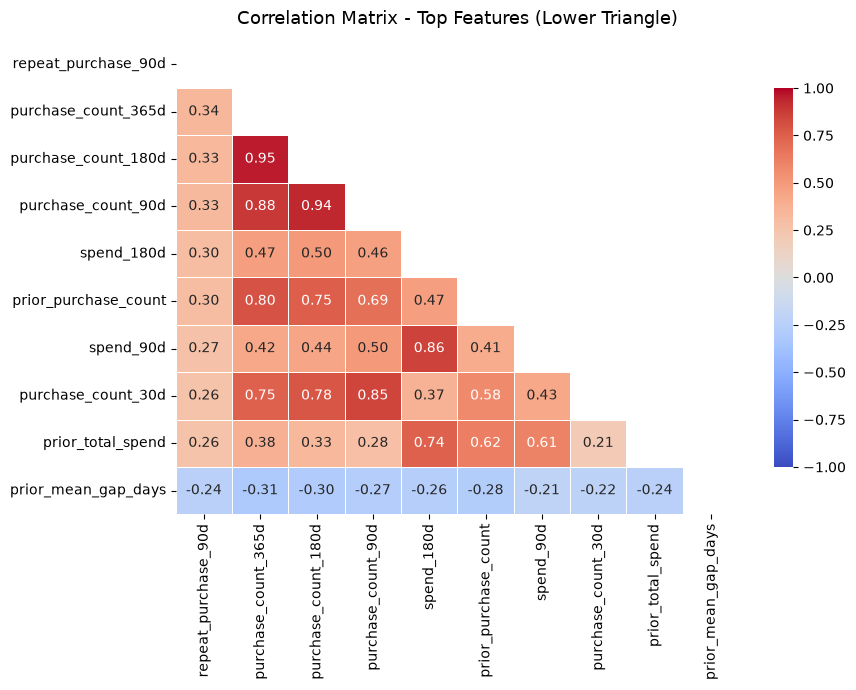

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Select numerical columns and the target
target = 'repeat_purchase_90d'
numeric_cols = [c for c in df_cleaned.columns if c != target and pd.api.types.is_numeric_dtype(df_cleaned[c])]


# Calculate correlations with the target
corr_series = df_cleaned[numeric_cols + [target]].corr()[target].sort_values(ascending=False)

print("--- Top 5 Positive Correlations with Repurchase ---")
print(corr_series.head(6))  # Includes the target itself (1.0)

print("\n--- Top 5 Negative Correlations with Repurchase ---")
print(corr_series.tail(5))

# Calculate the correlation matrix for the top features
top_corr_features = corr_series.abs().nlargest(10).index
corr_matrix = df_cleaned[top_corr_features].corr()

# Create a mask to hide the upper triangle
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

# Generate the heatmap with only the lower triangle
plt.figure(figsize=(9, 7))
sns.heatmap(
    corr_matrix, 
    mask=mask,          # Applies the upper triangle mask
    annot=True, 
    cmap='coolwarm', 
    fmt=".2f", 
    linewidths=0.5,
    vmin=-1, 
    vmax=1,
    cbar_kws={"shrink": .8}
)
plt.title("Correlation Matrix - Top Features (Lower Triangle)", fontsize=13, pad=12)
plt.tight_layout()
plt.show()




#### Summary of Insights from Correlation Analysis
* **Positive Drivers of Repurchase:** Variables related to historical engagement and monetary volume—such as prior spending and transaction counts—demonstrate the strongest positive correlations with repeat purchases, confirming that established, high-value customers are much more likely to return within 90 days.

* **Negative Correlations & Inactive Profiles:** Metrics capturing extended gaps or specific transactional constraints show negative associations with the target, highlighting that prolonged inactivity reduces the likelihood of a repeat purchase.

* **Multicollinearity Indicators:** The triangular correlation matrix reveals notable inter-correlations among historical spending and volume metrics. Recognizing these overlapping signals informs our subsequent feature selection strategy to remove redundant variables and prevent multicollinearity in our models.